In [9]:
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib.patches as mpatches

# Locate the repository root so the notebook works from the project or plot directory.
ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'PerfProfiler' / 'Predict_result' / 'predictions.json').is_file()
)
PREDICTIONS_PATH = ROOT / 'PerfProfiler' / 'Predict_result' / 'predictions.json'
BENCHMARK_ROOT = ROOT / 'PerfProfiler' / 'Workloads' / 'profile_results' / 'benchmark'

with PREDICTIONS_PATH.open(encoding='utf-8') as file:
    prediction_document = json.load(file)

# Convert current prediction records to the seconds-based structure used by the plots.
estimate_iteration_time_dict = {}
for record in prediction_document['predictions']:
    workload = record['workload']
    batch = str(record['batch_size'])
    gpu = record['target_gpu']
    estimate_iteration_time_dict.setdefault(workload, {}).setdefault(batch, {})[gpu] = (
        float(record['predicted_ms']) / 1000.0
    )

# Compute measured means directly from the current benchmark iteration CSV files.
measure_results_dict = {}
for workload_dir in BENCHMARK_ROOT.iterdir():
    if not workload_dir.is_dir():
        continue
    workload = workload_dir.name
    measure_results_dict[workload] = {}
    for gpu in ('P100', 'V100', 'A100'):
        gpu_dir = workload_dir / gpu
        if not gpu_dir.is_dir():
            continue
        for batch_dir in gpu_dir.glob('batch_*'):
            batch = batch_dir.name[6:]
            iterations_path = batch_dir / 'iterations.csv'
            with iterations_path.open(newline='', encoding='utf-8-sig') as file:
                rows = list(csv.DictReader(file))
            time_column = 'seconds' if rows and 'seconds' in rows[0] else 'latency_seconds'
            samples = [float(row[time_column]) for row in rows]
            mean_seconds = float(np.mean(samples))
            std_seconds = float(np.std(samples, ddof=1)) if len(samples) > 1 else 0.0
            measure_results_dict[workload].setdefault(batch, {})[gpu] = {
                'iteration_time': mean_seconds,
                'iteration_std_seconds': std_seconds,
                'iteration_count': len(samples)
            }


In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'Times New Roman'
rcParams['font.size'] = 20

In [11]:
cycleGAN_batch_size_list = [1, 2, 4]
ResNet50_batch_size_list = [128, 256, 512]
Transformer_batch_size_list = [512, 1024, 2048]
Qwen_batch_size_list = [1, 2, 4]
workload_list = ["CycleGAN", "ResNet50", "Transformers", "Qwen"]
GPU_model_list = ["P100", "V100", "A100"]
workload_batch_size_mapping = {
    "CycleGAN": cycleGAN_batch_size_list,
    "ResNet50": ResNet50_batch_size_list,
    "Transformers": Transformer_batch_size_list,
    "Qwen": Qwen_batch_size_list
}


CycleGAN


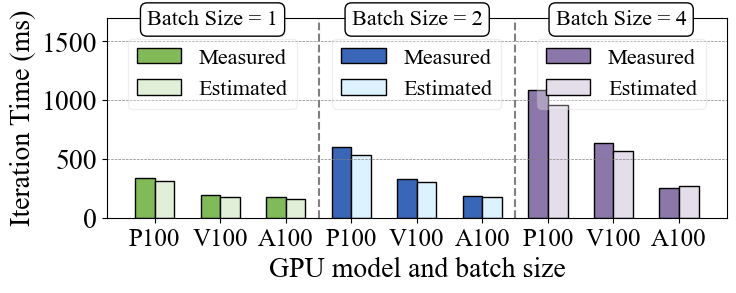

[0.07770596477138332, 0.08142299927255214, 0.09523457202820225, 0.10687363424419472, 0.07522241098280918, 0.02717124375532515, 0.11499999999999967, 0.11500000000000069, 0.07984576413040609]
0.08594184324276369
[336.09984290000006, 190.18825460000002, 175.2658742, 600.9894356000001, 330.15967599999993, 180.44616810000002, 1082.5885147, 637.4047689, 252.0024328]


In [12]:
workload = workload_list[0]
print(workload)
workload_measure = measure_results_dict.get(workload, {})
workload_estimate = estimate_iteration_time_dict.get(workload, {})
gpu_models = GPU_model_list
batch_sizes = workload_batch_size_mapping[workload]
# 合并数据
x_labels = []
predicted_times = []
actual_times = []

for batch in batch_sizes:
    x_labels.extend(['P100', 'V100', 'A100'])
    actual_times.extend([workload_measure[f'{batch}'][gpu]['iteration_time'] * 1000 for gpu in gpu_models])
    predicted_times.extend([workload_estimate[f'{batch}'][gpu] * 1000 for gpu in gpu_models])


x = np.arange(len(x_labels))  # 合并后的x轴索引
width = 0.3  # 柱状图宽度

fig, ax = plt.subplots(figsize=(8, 2.6))

# 定义颜色
bar_colors_predicted = ['#81bb59' if i < 3 else '#3966b7' if i < 6 else '#8b77a9' for i in range(len(x))]
bar_colors_actual = ['#e1efd9' if i < 3 else '#dcf2ff' if i < 6 else '#e3deea' for i in range(len(x))]

# 绘制预测运行时间的柱状图
ax.bar(x - width / 2, actual_times, width, label='Predicted Time', color=bar_colors_predicted, edgecolor='black')

# 绘制真实运行时间的柱状图
ax.bar(x + width / 2, predicted_times, width, label='Actual Time', color=bar_colors_actual, edgecolor='black')

# 添加标签和标题
ax.set_xlabel('GPU model and batch size')
ax.set_ylabel('Iteration Time (ms)')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=0, fontsize=18)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')
# 在指定位置绘制竖线
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=500, color='gray', linestyle='--')

batch_size_text_1 = "Batch Size = 1"
plt.text(0.065, 1.04, batch_size_text_1,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_2 = "Batch Size = 2"
plt.text(0.395, 1.04, batch_size_text_2,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_3 = "Batch Size = 4"
plt.text(0.724, 1.04, batch_size_text_3,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

legend_handles_group1 = [
    mpatches.Patch(facecolor='#81bb59', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e1efd9', label='Estimated', edgecolor='black')
]
legend_handles_group2 = [
    mpatches.Patch(facecolor='#3966b7', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#dcf2ff', label='Estimated', edgecolor='black')
]
legend_handles_group3 = [
    mpatches.Patch(facecolor='#8b77a9', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e3deea', label='Estimated', edgecolor='black')
]
legend1 = ax.legend(handles=legend_handles_group1, loc='upper center', bbox_to_anchor=(0.17, 0.95), fontsize=16)
ax.add_artist(legend1)
legend1.get_frame().set_alpha(0.3)
legend2 = ax.legend(handles=legend_handles_group2, loc='upper center', bbox_to_anchor=(0.5, 0.95), fontsize=16)
ax.add_artist(legend2)
legend2.get_frame().set_alpha(0.3)
legend3 = ax.legend(handles=legend_handles_group3, loc='upper center', bbox_to_anchor=(0.83, 0.95), fontsize=16)
legend3.get_frame().set_alpha(0.3)
plt.ylim(0, 1700)
ax.set_yticks([0, 500, 1000, 1500])

plt.savefig('cycleGAN_iteration.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_times, predicted_times)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)
print(actual_times)

ResNet50


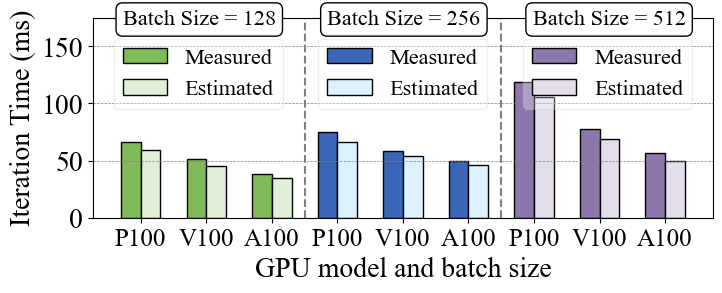

[0.11500000000000006, 0.11499999999999981, 0.09489687073453772, 0.11500000000000038, 0.08009922488245583, 0.08549154998226008, 0.11500000000000017, 0.1149999999999997, 0.11266336976786]
0.10535011281856818


In [13]:
workload = workload_list[1]
print(workload)
workload_measure = measure_results_dict.get(workload, {})
workload_estimate = estimate_iteration_time_dict.get(workload, {})
gpu_models = GPU_model_list
batch_sizes = workload_batch_size_mapping[workload]
# 合并数据
x_labels = []
predicted_times = []
actual_times = []

for batch in batch_sizes:
    x_labels.extend(['P100', 'V100', 'A100'])
    actual_times.extend([workload_measure[f'{batch}'][gpu]['iteration_time'] * 1000 for gpu in gpu_models])
    predicted_times.extend([workload_estimate[f'{batch}'][gpu] * 1000 for gpu in gpu_models])


x = np.arange(len(x_labels))  # 合并后的x轴索引
width = 0.3  # 柱状图宽度

fig, ax = plt.subplots(figsize=(8, 2.6))

# 定义颜色
bar_colors_predicted = ['#81bb59' if i < 3 else '#3966b7' if i < 6 else '#8b77a9' for i in range(len(x))]
bar_colors_actual = ['#e1efd9' if i < 3 else '#dcf2ff' if i < 6 else '#e3deea' for i in range(len(x))]

# 绘制预测运行时间的柱状图
ax.bar(x - width / 2, actual_times, width, label='Predicted Time', color=bar_colors_predicted, edgecolor='black')

# 绘制真实运行时间的柱状图
ax.bar(x + width / 2, predicted_times, width, label='Actual Time', color=bar_colors_actual, edgecolor='black')

# 添加标签和标题
ax.set_xlabel('GPU model and batch size')
ax.set_ylabel('Iteration Time (ms)')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=0, fontsize=18)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')
# 在指定位置绘制竖线
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=500, color='gray', linestyle='--')

batch_size_text_1 = "Batch Size = 128"
plt.text(0.048, 1.04, batch_size_text_1,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_2 = "Batch Size = 256"
plt.text(0.378, 1.04, batch_size_text_2,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_3 = "Batch Size = 512"
plt.text(0.709, 1.04, batch_size_text_3,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

legend_handles_group1 = [
    mpatches.Patch(facecolor='#81bb59', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e1efd9', label='Estimated', edgecolor='black')
]
legend_handles_group2 = [
    mpatches.Patch(facecolor='#3966b7', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#dcf2ff', label='Estimated', edgecolor='black')
]
legend_handles_group3 = [
    mpatches.Patch(facecolor='#8b77a9', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e3deea', label='Estimated', edgecolor='black')
]
legend1 = ax.legend(handles=legend_handles_group1, loc='upper center', bbox_to_anchor=(0.17, 0.95), fontsize=16)
ax.add_artist(legend1)
legend1.get_frame().set_alpha(0.3)
legend2 = ax.legend(handles=legend_handles_group2, loc='upper center', bbox_to_anchor=(0.5, 0.95), fontsize=16)
ax.add_artist(legend2)
legend2.get_frame().set_alpha(0.3)
legend3 = ax.legend(handles=legend_handles_group3, loc='upper center', bbox_to_anchor=(0.83, 0.95), fontsize=16)
legend3.get_frame().set_alpha(0.3)
plt.ylim(0, 175)
ax.set_yticks([0, 50, 100, 150])

plt.savefig('ResNet50_iteration.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_times, predicted_times)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)

Transformers


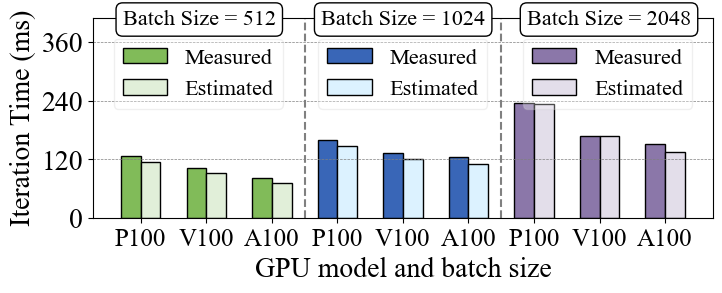

[0.10146683029450325, 0.0924024545607874, 0.1071781022934736, 0.08233367743585354, 0.09047349206351744, 0.11402002879360781, 0.003971832348318646, 0.008567576060438961, 0.1010147443957109]
0.07793652647180128


In [14]:
workload = workload_list[2]
print(workload)
workload_measure = measure_results_dict.get(workload, {})
workload_estimate = estimate_iteration_time_dict.get(workload, {})
gpu_models = GPU_model_list
batch_sizes = workload_batch_size_mapping[workload]
# 合并数据
x_labels = []
predicted_times = []
actual_times = []

for batch in batch_sizes:
    x_labels.extend(['P100', 'V100', 'A100'])
    actual_times.extend([workload_measure[f'{batch}'][gpu]['iteration_time'] * 1000 for gpu in gpu_models])
    predicted_times.extend([workload_estimate[f'{batch}'][gpu] * 1000 for gpu in gpu_models])


x = np.arange(len(x_labels))  # 合并后的x轴索引
width = 0.3  # 柱状图宽度

fig, ax = plt.subplots(figsize=(8, 2.6))

# 定义颜色
bar_colors_predicted = ['#81bb59' if i < 3 else '#3966b7' if i < 6 else '#8b77a9' for i in range(len(x))]
bar_colors_actual = ['#e1efd9' if i < 3 else '#dcf2ff' if i < 6 else '#e3deea' for i in range(len(x))]

# 绘制预测运行时间的柱状图
ax.bar(x - width / 2, actual_times, width, label='Predicted Time', color=bar_colors_predicted, edgecolor='black')

# 绘制真实运行时间的柱状图
ax.bar(x + width / 2, predicted_times, width, label='Actual Time', color=bar_colors_actual, edgecolor='black')

# 添加标签和标题
ax.set_xlabel('GPU model and batch size')
ax.set_ylabel('Iteration Time (ms)')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=0, fontsize=18)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')
# 在指定位置绘制竖线
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=500, color='gray', linestyle='--')

batch_size_text_1 = "Batch Size = 512"
plt.text(0.048, 1.04, batch_size_text_1,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_2 = "Batch Size = 1024"
plt.text(0.368, 1.04, batch_size_text_2,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_3 = "Batch Size = 2048"
plt.text(0.7, 1.04, batch_size_text_3,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

legend_handles_group1 = [
    mpatches.Patch(facecolor='#81bb59', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e1efd9', label='Estimated', edgecolor='black')
]
legend_handles_group2 = [
    mpatches.Patch(facecolor='#3966b7', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#dcf2ff', label='Estimated', edgecolor='black')
]
legend_handles_group3 = [
    mpatches.Patch(facecolor='#8b77a9', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e3deea', label='Estimated', edgecolor='black')
]
legend1 = ax.legend(handles=legend_handles_group1, loc='upper center', bbox_to_anchor=(0.17, 0.95), fontsize=16)
ax.add_artist(legend1)
legend1.get_frame().set_alpha(0.3)
legend2 = ax.legend(handles=legend_handles_group2, loc='upper center', bbox_to_anchor=(0.5, 0.95), fontsize=16)
ax.add_artist(legend2)
legend2.get_frame().set_alpha(0.3)
legend3 = ax.legend(handles=legend_handles_group3, loc='upper center', bbox_to_anchor=(0.83, 0.95), fontsize=16)
legend3.get_frame().set_alpha(0.3)
plt.ylim(0, 410)
ax.set_yticks([0, 120, 240, 360])

plt.savefig('Transformers_iteration.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_times, predicted_times)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)

Qwen


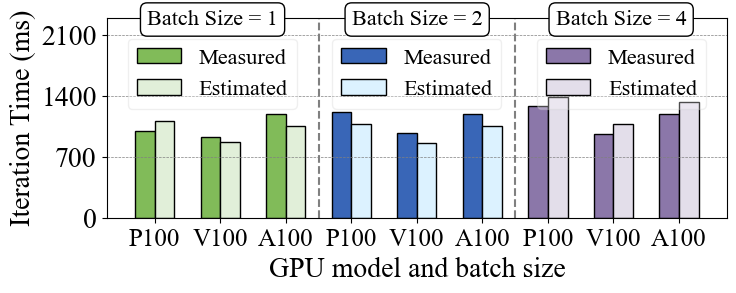

[0.1149999999999631, 0.05844160022931673, 0.11499999999999122, 0.115000000000028, 0.11499999999999189, 0.11499999999999536, 0.08095113149032075, 0.115000000000014, 0.11500000000000102]
0.10493252574662466
[994.5276671, 927.5055210999999, 1192.549184, 1212.0512628, 973.0640312, 1192.0078747, 1287.6659685, 964.2174848000001, 1194.3817881]


In [15]:
workload = workload_list[3]
print(workload)
workload_measure = measure_results_dict.get(workload, {})
workload_estimate = estimate_iteration_time_dict.get(workload, {})
gpu_models = GPU_model_list
batch_sizes = workload_batch_size_mapping[workload]
# 合并数据
x_labels = []
predicted_times = []
actual_times = []

for batch in batch_sizes:
    x_labels.extend(['P100', 'V100', 'A100'])
    actual_times.extend([workload_measure[f'{batch}'][gpu]['iteration_time'] * 1000 for gpu in gpu_models])
    predicted_times.extend([workload_estimate[f'{batch}'][gpu] * 1000 for gpu in gpu_models])


x = np.arange(len(x_labels))  # 合并后的x轴索引
width = 0.3  # 柱状图宽度

fig, ax = plt.subplots(figsize=(8, 2.6))

# 定义颜色
bar_colors_predicted = ['#81bb59' if i < 3 else '#3966b7' if i < 6 else '#8b77a9' for i in range(len(x))]
bar_colors_actual = ['#e1efd9' if i < 3 else '#dcf2ff' if i < 6 else '#e3deea' for i in range(len(x))]

# 绘制预测运行时间的柱状图
ax.bar(x - width / 2, actual_times, width, label='Predicted Time', color=bar_colors_predicted, edgecolor='black')

# 绘制真实运行时间的柱状图
ax.bar(x + width / 2, predicted_times, width, label='Actual Time', color=bar_colors_actual, edgecolor='black')

# 添加标签和标题
ax.set_xlabel('GPU model and batch size')
ax.set_ylabel('Iteration Time (ms)')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=0, fontsize=18)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')
# 在指定位置绘制竖线
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=500, color='gray', linestyle='--')

batch_size_text_1 = "Batch Size = 1"
plt.text(0.065, 1.04, batch_size_text_1,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_2 = "Batch Size = 2"
plt.text(0.395, 1.04, batch_size_text_2,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))
batch_size_text_3 = "Batch Size = 4"
plt.text(0.724, 1.04, batch_size_text_3,
         ha='left', va='top', transform=plt.gca().transAxes,
         fontsize=16, color='black',
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

legend_handles_group1 = [
    mpatches.Patch(facecolor='#81bb59', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e1efd9', label='Estimated', edgecolor='black')
]
legend_handles_group2 = [
    mpatches.Patch(facecolor='#3966b7', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#dcf2ff', label='Estimated', edgecolor='black')
]
legend_handles_group3 = [
    mpatches.Patch(facecolor='#8b77a9', label='Measured', edgecolor='black'),
    mpatches.Patch(facecolor='#e3deea', label='Estimated', edgecolor='black')
]
legend1 = ax.legend(handles=legend_handles_group1, loc='upper center', bbox_to_anchor=(0.17, 0.95), fontsize=16)
ax.add_artist(legend1)
legend1.get_frame().set_alpha(0.3) 
legend2 = ax.legend(handles=legend_handles_group2, loc='upper center', bbox_to_anchor=(0.5, 0.95), fontsize=16)
ax.add_artist(legend2)
legend2.get_frame().set_alpha(0.3) 
legend3 = ax.legend(handles=legend_handles_group3, loc='upper center', bbox_to_anchor=(0.83, 0.95), fontsize=16)
legend3.get_frame().set_alpha(0.3) 
plt.ylim(0, 2300)
ax.set_yticks([0, 700, 1400, 2100])

plt.savefig('Qwen_iteration.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_times, predicted_times)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)
print(actual_times)

In [16]:
# Summarize run-to-run variation for every measured workload, batch size, and GPU.
print("Measured benchmark means and sample standard deviations (ms)")
print("Workload       | Batch | GPU  | Runs | Mean (ms) | SD (ms) | Relative SD (%)")
print("---------------|------:|------|-----:|----------:|--------:|----------------:")
for workload in sorted(measure_results_dict):
    batches = sorted(measure_results_dict[workload], key=int)
    for batch in batches:
        for gpu in GPU_model_list:
            measured = measure_results_dict[workload][batch][gpu]
            mean_ms = measured["iteration_time"] * 1000
            std_ms = measured["iteration_std_seconds"] * 1000
            relative_std = std_ms / mean_ms * 100 if mean_ms else 0.0
            print(f"{workload:<14} | {int(batch):>5} | {gpu:<4} | "
                  f"{measured['iteration_count']:>4} | {mean_ms:>9.3f} | "
                  f"{std_ms:>7.3f} | {relative_std:>15.3f}")


Measured benchmark means and sample standard deviations (ms)
Workload       | Batch | GPU  | Runs | Mean (ms) | SD (ms) | Relative SD (%)
---------------|------:|------|-----:|----------:|--------:|----------------:
CycleGAN       |     1 | P100 |   10 |   336.100 |   0.547 |           0.163
CycleGAN       |     1 | V100 |   10 |   190.188 |   0.047 |           0.025
CycleGAN       |     1 | A100 |   10 |   175.266 |   0.784 |           0.447
CycleGAN       |     2 | P100 |   10 |   600.989 |   0.852 |           0.142
CycleGAN       |     2 | V100 |   10 |   330.160 |   0.029 |           0.009
CycleGAN       |     2 | A100 |   10 |   180.446 |   0.862 |           0.477
CycleGAN       |     4 | P100 |   10 |  1082.589 |   1.975 |           0.182
CycleGAN       |     4 | V100 |   10 |   637.405 |   0.085 |           0.013
CycleGAN       |     4 | A100 |   10 |   252.002 |   0.564 |           0.224
Qwen           |     1 | P100 |   10 |   994.528 |  10.890 |           1.095
Qwen          